In [1]:
import json
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, ConfusionMatrixDisplay, RocCurveDisplay)
from sklearn.inspection import permutation_importance
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

sns.set_theme(style="whitegrid")

train = pd.read_csv("../data/processed/train.csv", parse_dates=["StartDatetime", "EndDatetime"])
test = pd.read_csv("../data/processed/test.csv", parse_dates=["StartDatetime", "EndDatetime"])

with open("../models/feature_columns.json") as file:
    settings = json.load(file)
FEATURES = settings["features"]
print("High Demand threshold (train median):", settings["high_demand_threshold"])    # 14.2

X_train, y_train = train[FEATURES], train["HighDemand"]
X_test, y_test = test[FEATURES], test["HighDemand"]

High Demand threshold (train median): 14.2


               Train   Test
Normal Demand    0.5  0.512
High Demand      0.5  0.488


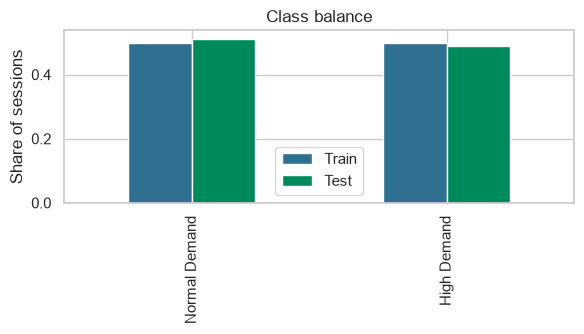

In [2]:
balance = pd.DataFrame({
    "Train": y_train.value_counts(normalize=True),
    "Test": y_test.value_counts(normalize=True),
}).round(3)
balance.index = ["Normal Demand", "High Demand"]
print(balance)

balance.plot(kind="bar", figsize=(6, 3.5), color=["#2F6F8F", "#00895C"])
plt.title("Class balance")
plt.ylabel("Share of sessions")
plt.tight_layout()
plt.savefig("../docs/figures/15_class_balance.png", dpi=150, bbox_inches="tight")
plt.show()

In [3]:
def get_score(model, X):
    """Probability of High Demand, or the SVM's decision score. Both work for ROC-AUC."""
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X)[:, 1]
    return model.decision_function(X)


def evaluate(model, name):
    predictions = model.predict(X_test)
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions),
        "F1": f1_score(y_test, predictions),
        "ROC_AUC": roc_auc_score(y_test, get_score(model, X_test)),
    }

In [4]:
models = {
    "Baseline (most frequent)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=200, max_depth=12, min_samples_leaf=20, n_jobs=-1, random_state=42),
    "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=25, n_jobs=-1)),
    "SVM": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, random_state=42)),
    "XGBoost": XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=5, subsample=0.8,
        colsample_bytree=0.8, random_state=42, n_jobs=-1, eval_metric="logloss"),
    "LightGBM": LGBMClassifier(
        n_estimators=300, learning_rate=0.05, num_leaves=31, random_state=42, verbose=-1),
}

# An RBF SVM gets very slow on 58,000 rows (training time grows roughly with the square of the rows).
# So the SVM learns from a random 15,000-row sample. We say so in the results table.
svm_sample = X_train.sample(15000, random_state=42)
svm_labels = y_train.loc[svm_sample.index]

In [5]:
rows, fitted = [], {}

for name, model in models.items():
    start = time.time()
    if name == "SVM":
        model.fit(svm_sample, svm_labels)
        label = "SVM (15k sample)"
    else:
        model.fit(X_train, y_train)
        label = name
    fitted[label] = model
    result = evaluate(model, label)
    rows.append(result)
    print(f"{label:26s} AUC={result['ROC_AUC']:.3f}  F1={result['F1']:.3f}  ({time.time() - start:.0f}s)")

results = pd.DataFrame(rows).set_index("Model").sort_values("ROC_AUC", ascending=False)
results.round(3)

Baseline (most frequent)   AUC=0.500  F1=0.655  (0s)
Logistic Regression        AUC=0.787  F1=0.702  (0s)
Decision Tree              AUC=0.789  F1=0.709  (0s)
Random Forest              AUC=0.805  F1=0.735  (2s)
KNN                        AUC=0.777  F1=0.710  (6s)
SVM (15k sample)           AUC=0.784  F1=0.729  (34s)
XGBoost                    AUC=0.806  F1=0.739  (2s)
LightGBM                   AUC=0.806  F1=0.739  (2s)


,Accuracy,Precision,Recall,F1,ROC_AUC
Model,,,,,
LightGBM,0.728,0.694,0.790,0.739,0.806
XGBoost,0.726,0.691,0.793,0.739,0.806
Random Forest,0.725,0.693,0.783,0.735,0.805
Decision Tree,0.708,0.691,0.728,0.709,0.789
Logistic Regression,0.706,0.693,0.712,0.702,0.787
SVM (15k sample),0.717,0.684,0.781,0.729,0.784
KNN,0.704,0.681,0.741,0.710,0.777
Baseline (most frequent),0.488,0.488,1.000,0.655,0.500


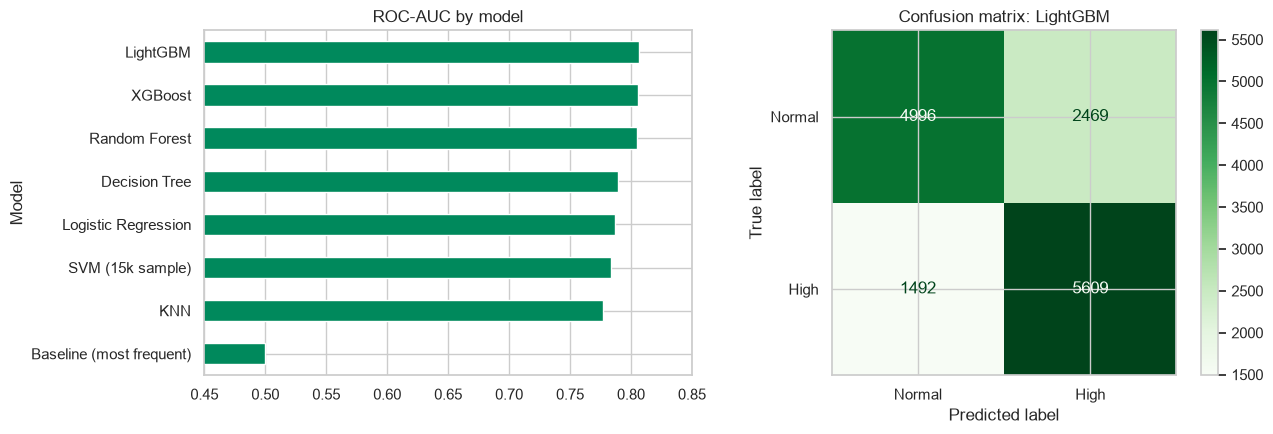

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

results["ROC_AUC"].sort_values().plot(kind="barh", ax=axes[0], color="#00895C")
axes[0].set_xlim(0.45, 0.85)
axes[0].set_title("ROC-AUC by model")

best_name = results.index[0]
best_model = fitted[best_name]
ConfusionMatrixDisplay.from_predictions(
    y_test, best_model.predict(X_test),
    display_labels=["Normal", "High"], cmap="Greens", ax=axes[1])
axes[1].set_title(f"Confusion matrix: {best_name}")

plt.tight_layout()
plt.savefig("../docs/figures/16_classification_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

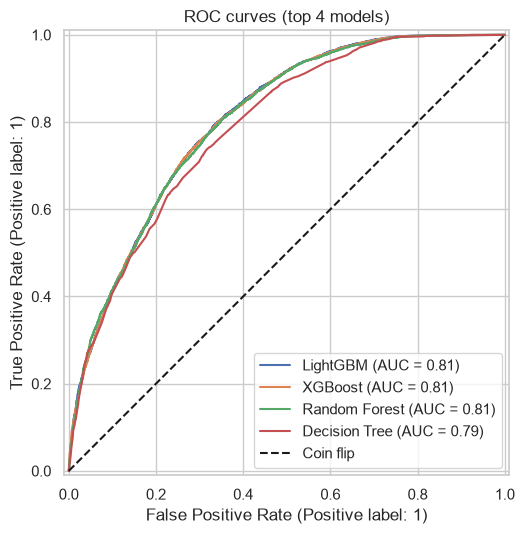

In [7]:
plt.figure(figsize=(6.5, 5.5))
for name in results.index[:4]:
    RocCurveDisplay.from_predictions(y_test, get_score(fitted[name], X_test), name=name, ax=plt.gca())
plt.plot([0, 1], [0, 1], "k--", label="Coin flip")
plt.title("ROC curves (top 4 models)")
plt.legend()
plt.tight_layout()
plt.savefig("../docs/figures/17_roc_curves.png", dpi=150, bbox_inches="tight")
plt.show()

Drop in ROC-AUC when the feature is shuffled:
UserPrevAvgDemand       0.1473
ChargerPrevAvgDemand    0.0402
Hour                    0.0362
ChargerType             0.0152
UserPrevSessions        0.0132
ChargerPrevSessions     0.0026
Loc_resort              0.0018
Loc_market              0.0018
Loc_apartment           0.0017
Loc_public_area         0.0012
dtype: float64


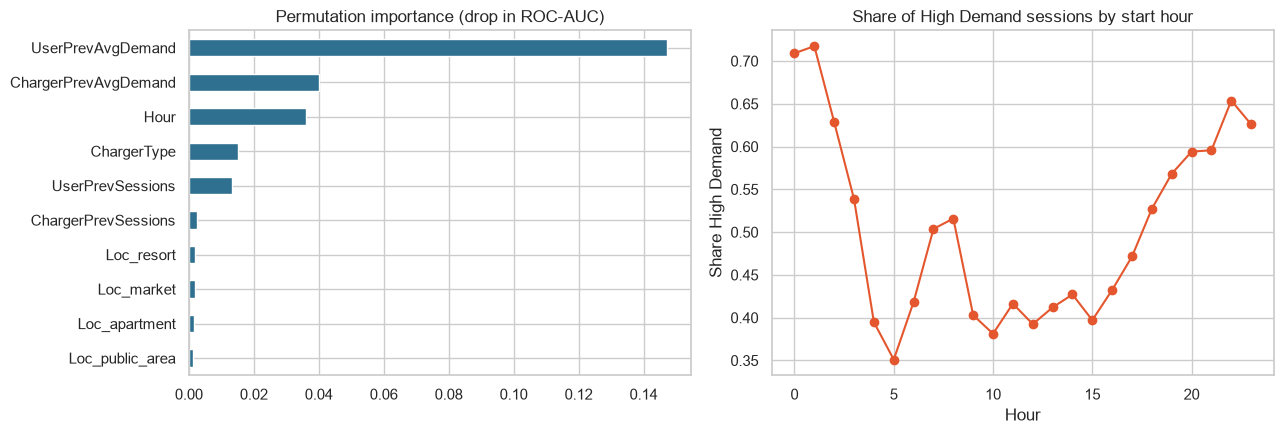

In [8]:
perm = permutation_importance(
    best_model, X_test, y_test, n_repeats=5, random_state=42, scoring="roc_auc", n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)
print("Drop in ROC-AUC when the feature is shuffled:")
print(importance.head(10).round(4))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
importance.head(10).sort_values().plot(kind="barh", ax=axes[0], color="#2F6F8F")
axes[0].set_title("Permutation importance (drop in ROC-AUC)")

test.groupby("Hour")["HighDemand"].mean().plot(marker="o", ax=axes[1], color="#E4572E")
axes[1].set_title("Share of High Demand sessions by start hour")
axes[1].set_ylabel("Share High Demand")

plt.tight_layout()
plt.savefig("../docs/figures/18_high_demand_factors.png", dpi=150, bbox_inches="tight")
plt.show()

In [10]:
from imblearn.over_sampling import RandomOverSampler, SMOTE, ADASYN

# A STRICTER target: "Peak" = top 10% of demand. Now the classes really are imbalanced.
peak_threshold = train["Demand"].quantile(0.90)
y_train_peak = (train["Demand"] >= peak_threshold).astype(int)
y_test_peak = (test["Demand"] >= peak_threshold).astype(int)

print("Peak threshold:", round(peak_threshold, 1))                                # about 37.2
print("Peak share  train:", round(y_train_peak.mean(), 3), "| test:", round(y_test_peak.mean(), 3))
print("Accuracy of always guessing 'not peak':", round(1 - y_test_peak.mean(), 3))   # about 0.89


def make_peak_model(class_weight=None):
    return LGBMClassifier(n_estimators=200, learning_rate=0.05, num_leaves=31,
                          class_weight=class_weight, random_state=42, verbose=-1)


experiments = [
    ("No resampling", None, None),
    ("class_weight='balanced'", None, "balanced"),
    ("Random oversampling", RandomOverSampler(random_state=42), None),
    ("SMOTE", SMOTE(random_state=42), None),
    ("ADASYN", ADASYN(random_state=42), None),
]

peak_rows = []
for name, sampler, class_weight in experiments:
    if sampler is None:
        X_fit, y_fit = X_train, y_train_peak
    else:
        # Resample the TRAINING data only. The test set must stay untouched and realistic.
        X_fit, y_fit = sampler.fit_resample(X_train, y_train_peak)

    model = make_peak_model(class_weight).fit(X_fit, y_fit)
    predictions = model.predict(X_test)
    peak_rows.append({
        "Method": name,
        "Rows_used_to_train": len(X_fit),
        "Accuracy": accuracy_score(y_test_peak, predictions),
        "Precision": precision_score(y_test_peak, predictions, zero_division=0),
        "Recall": recall_score(y_test_peak, predictions),
        "F1": f1_score(y_test_peak, predictions),
        "ROC_AUC": roc_auc_score(y_test_peak, model.predict_proba(X_test)[:, 1]),
    })

peak_results = pd.DataFrame(peak_rows).set_index("Method")
peak_results.round(3)

Peak threshold: 37.2
Peak share  train: 0.1 | test: 0.11
Accuracy of always guessing 'not peak': 0.89


,Rows_used_to_train,Accuracy,Precision,Recall,F1,ROC_AUC
Method,,,,,,
No resampling,58260,0.899,0.594,0.265,0.367,0.862
class_weight='balanced',58260,0.781,0.302,0.753,0.431,0.863
Random oversampling,104864,0.784,0.302,0.741,0.429,0.859
SMOTE,104864,0.765,0.286,0.760,0.416,0.847
ADASYN,105242,0.782,0.299,0.735,0.425,0.848


In [11]:
results.round(4).to_csv("../models/classification_results.csv")
peak_results.round(4).to_csv("../models/imbalance_experiment.csv")
joblib.dump(best_model, "../models/best_classifier.pkl")
print("Saved. Best classifier:", best_name)

Saved. Best classifier: LightGBM
